# helio_foxes: one observation, three FOXES models

This notebook demonstrates the public `helio_foxes` API with one processed seven-channel SDO/AIA observation. It fetches HARP active regions and a measured GOES XRS sample, compares three local model checkpoints, maps patch flux, and shows Gaussian uncertainty.

 Set a real JSOC email below. The observation fetch needs internet access and can take several minutes. GOES and HARP data are supplementary; either may be unavailable. 

Checkpoints are read from `forecasting/trained_weights_and_normalization/`
in the installed editable checkout; no checkpoint copies are needed in this demo
folder. Saved observation archives in `saved_observations/` are tracked with Git LFS.
Run from this demo folder to keep saved observations here.


In [ ]:
from pathlib import Path
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import helio_foxes

DEMO_DIR = Path.cwd()
JSOC_EMAIL = "ggoodwin5@gsu.edu"  # Replace with your registered JSOC email.
TIMESTAMP = "2023-07-11T01:30:00Z"
WEIGHTS_DIR = (
    Path(helio_foxes.__file__).resolve().parents[1]
    / "forecasting" / "trained_weights_and_normalization"
)
CHECKPOINTS = {
    "Complex Gaussian": WEIGHTS_DIR / "updated_architecture_checkpoints" / "ComplexModel.ckpt",
    "Lighter Gaussian": WEIGHTS_DIR / "updated_architecture_checkpoints" / "SlightlyLighterModel.ckpt",
    "Deterministic": WEIGHTS_DIR / "inverted-attention-mask.ckpt",
}

if JSOC_EMAIL == "you@example.com":
    raise ValueError("Set JSOC_EMAIL to your registered email before fetching AIA/HARP data.")
missing = [str(path) for path in CHECKPOINTS.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing checkpoints: {missing}. Download the checkpoint LFS files in forecasting/trained_weights_and_normalization/.")
print("helio_foxes:", helio_foxes.__file__)
print("Demo folder:", DEMO_DIR)
print("Checkpoints:", ", ".join(CHECKPOINTS))
processor = helio_foxes.ObservationProcessor(
    email=JSOC_EMAIL,
    include_aia=True,
    include_harps=True,
    include_sxr=True,
    harp_bbox_expansion=0.2,
)

## 1. Fetch one observation

`ObservationProcessor` processes AIA into a `(7, 512, 512)` array, projects HARP boxes onto the same crop, and looks up measured GOES XRS flux. The 20% HARP expansion applies on each side of a box and is used for both regional sums and plot outlines. Raw downloads are temporary.

In [2]:
observation = processor.fetch_observation(TIMESTAMP)
print("Requested UTC:", observation.metadata.timestamp)
print("AIA shape:", observation.data.shape)
print("AIA wavelengths (Å):", observation.metadata.wavelengths)
print("HARP regions:", "not requested" if observation.harp_regions is None else len(observation.harp_regions))
print("GOES XRS:", "available" if observation.sxr is not None else "unavailable")

2026-10-29 16:23:15 - root - INFO: Start download: 2023-07-11T01:30:00
2026-10-29 16:23:18 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM5/D1654565545/S00000/image_lev1.fits
2026-10-29 16:23:18 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM3/D1831895816/D1654565550/S00000/image_lev1.fits
2026-10-29 16:23:18 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM80/D1654565546/S00000/image_lev1.fits
2026-10-29 16:23:18 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM11/D1831915410/D1654565553/S00000/image_lev1.fits
2026-10-29 16:23:31 - sunpy - WARNING: SunpyMetadataWarning: The meta key date__obs is too long, dropping from the FITS header (maximum allowed key length is 8 characters).
2026-10-29 16:23:31 - sunpy - WARNING: SunpyMetadataWarning: The meta key oscnmean has a NaN value, which is not valid in a FITS header, dropping from the FITS header
2026-10-29 16:23:31 - sunpy - WARNING: SunpyMetadataWarning: The meta key oscnrms has a NaN value, which is not

Requested UTC: 2023-07-11 01:30:00+00:00
AIA shape: (7, 512, 512)
AIA wavelengths (Å): (94, 131, 171, 193, 211, 304, 335)
HARP regions: 14
GOES XRS: available


### The seven AIA inputs

These are the processed model inputs in channel order. Each panel uses its own percentile stretch for display; the arrays passed to FOXES are unchanged.

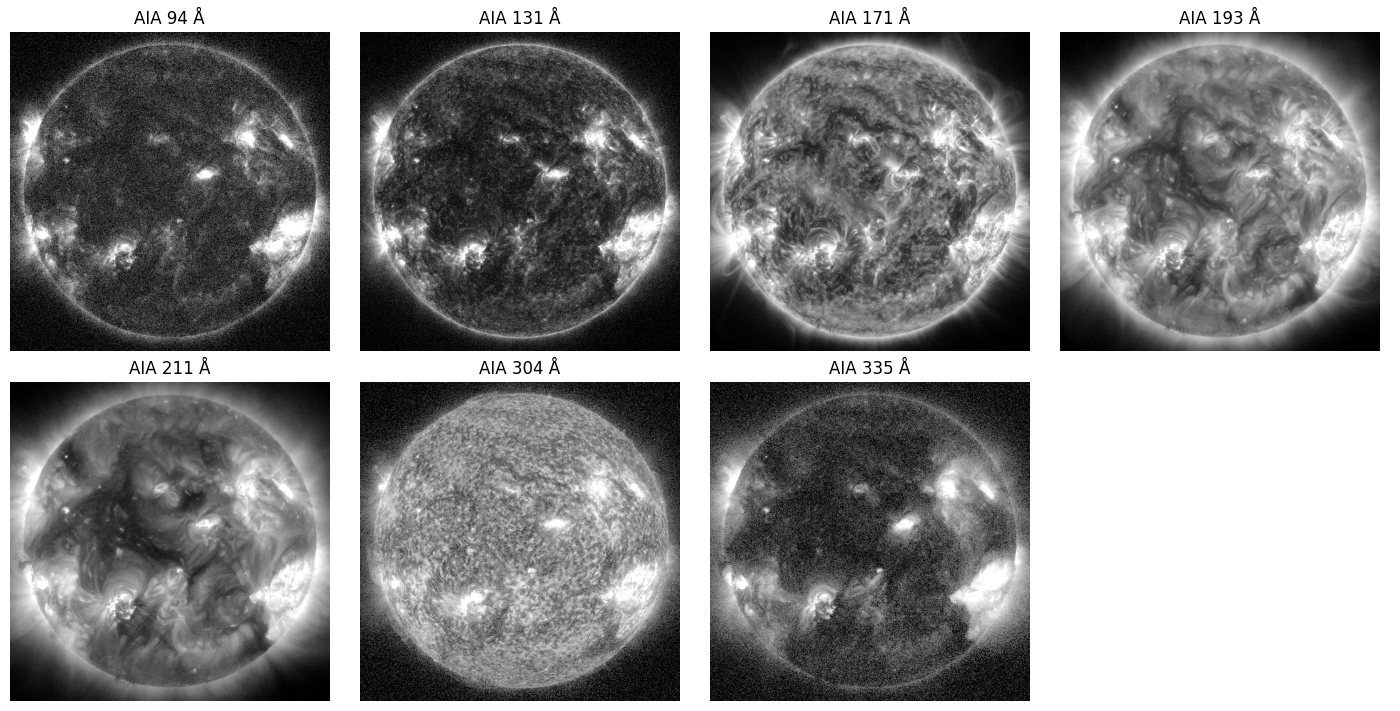

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
for ax, wavelength, image in zip(axes.flat, observation.metadata.wavelengths, observation.data):
    low, high = np.percentile(image, [1, 99])
    ax.imshow(image, origin="lower", cmap="gray", vmin=low, vmax=high)
    ax.set_title(f"AIA {wavelength} Å")
    ax.axis("off")
for ax in axes.flat[len(observation.metadata.wavelengths):]:
    ax.axis("off")
plt.show()

## 2. Run the three checkpoints

`load_model` creates a reusable predictor. Here each model sees the **same** observation; models are released after prediction to limit accelerator memory use. `Prediction.flux` is full-disk soft X-ray flux in W/m². `flux_map` contains the model's patch contributions. The deterministic model has no uncertainty intervals.

In [4]:
predictions = {}
for name, checkpoint in CHECKPOINTS.items():
    print(f"Loading {name} from {checkpoint.name} …")
    model = helio_foxes.load_model(checkpoint, device="auto")
    predictions[name] = helio_foxes.predict(observation, model=model)
    print(f"  full-disk prediction: {predictions[name].flux:.3e} W/m²")
    del model
    gc.collect()

summary = pd.DataFrame([
    {
        "Model": name,
        "Predicted XRS-B (W/m²)": result.flux,
        "68% lower (W/m²)": result.intervals["68"][0] if result.intervals else np.nan,
        "68% upper (W/m²)": result.intervals["68"][1] if result.intervals else np.nan,
        "95% lower (W/m²)": result.intervals["95"][0] if result.intervals else np.nan,
        "95% upper (W/m²)": result.intervals["95"][1] if result.intervals else np.nan,
    }
    for name, result in predictions.items()
]).set_index("Model")
display(summary.style.format("{:.3e}", na_rep="—"))

Loading Complex Gaussian from ComplexModel.ckpt …
Using mps for inference
Loading CoupledGaussianViTLocal model...
  full-disk prediction: 2.695e-06 W/m²
Loading Lighter Gaussian from SlightlyLighterModel.ckpt …
Using mps for inference
Loading CoupledGaussianViTLocal model...
  full-disk prediction: 2.947e-06 W/m²
Loading Deterministic from inverted-attention-mask.ckpt …
Using mps for inference
Loading ViTLocal model...
  full-disk prediction: 2.899e-06 W/m²


,Predicted XRS-B (W/m²),68% lower (W/m²),68% upper (W/m²),95% lower (W/m²),95% upper (W/m²)
Model,,,,,
Complex Gaussian,2.695e-06,2.288e-06,3.173e-06,1.955e-06,3.713e-06
Lighter Gaussian,2.947e-06,2.198e-06,3.950e-06,1.658e-06,5.231e-06
Deterministic,2.899e-06,—,—,—,—


### Compare with the measured GOES sample

GOES XRS-B (1–8 Å) is a measured comparison value, **not an input to the model**. It may be missing if no valid sample was available. The sample timestamp can differ from the requested AIA time.

In [5]:
sxr = observation.sxr
if sxr is None:
    print("No usable GOES XRS sample was returned for this time.")
else:
    print("GOES sample UTC:", sxr["timestamp"])
    print("Offset from requested time (s):", sxr["time_offset_seconds"])
    print("Contributing satellites:", ", ".join(sxr["satellites"]))
    print(f"Measured XRS-B: {sxr['xrsb_flux']:.3e} W/m²")
    if sxr["xrsa_flux"] is not None:
        print(f"Measured XRS-A: {sxr['xrsa_flux']:.3e} W/m²")
    display(pd.DataFrame([
        {"Model": name, "Predicted / measured XRS-B": result.flux / sxr["xrsb_flux"]}
        for name, result in predictions.items()
    ]).set_index("Model").style.format("{:.2f}×"))

GOES sample UTC: 2023-07-11 01:30:00+00:00
Offset from requested time (s): 0.0
Contributing satellites: GOES-18, GOES-16
Measured XRS-B: 2.941e-06 W/m²
Measured XRS-A: 8.626e-08 W/m²


,Predicted / measured XRS-B
Model,
Complex Gaussian,0.92×
Lighter Gaussian,1.00×
Deterministic,0.99×


## 3. Full-disk map and HARP contributions

Use the Complex Gaussian checkpoint for the spatial examples. Each `harp_regions` row retains its JSOC metadata and gains a predicted flux sum. HARP boxes may overlap, so their sums do not have to add up to the full-disk flux. The plot uses a 1e-7 W/m² display threshold to keep labels readable; the table retains every returned region.

,HARP,NOAA ARs,Flux sum (W/m²),Variance contribution (W/m²),Top (%),Left (%),Width (%),Height (%)
0,9751,"13358,13359,13366,13368,13369",1.071e-06,1.861e-07,54.0,67.6,29.6,19.0
2,9762,13361,1.829e-07,4.003e-08,24.0,63.6,20.0,16.7
9,9793,13367,1.707e-07,7.613e-08,40.3,52.1,16.9,8.2
5,9781,13363,1.142e-07,2.265e-08,62.5,18.8,29.5,13.0
1,9752,13360,9.506e-08,2.796e-08,26.3,79.4,11.3,12.5
10,9796,"13370,13371",7.476e-08,2.170e-08,59.4,5.0,11.0,7.6
13,9802,13372,1.825e-08,1.169e-08,31.0,7.2,1.7,4.0
12,9798,MISSING,6.820e-09,4.016e-09,59.4,18.2,4.0,2.9
11,9797,MISSING,5.155e-09,2.619e-09,60.6,47.4,4.3,4.9
3,9770,MISSING,3.040e-09,1.070e-09,45.0,74.4,7.6,4.5


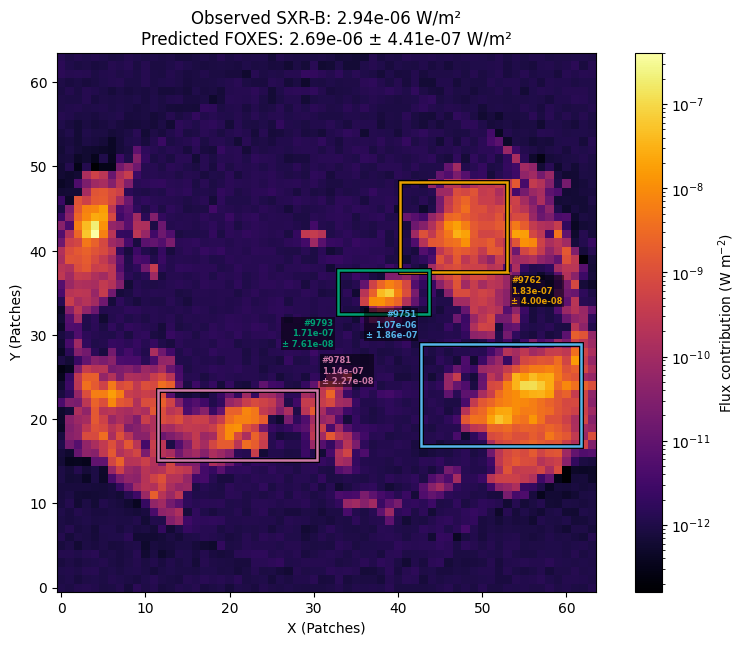

In [6]:
result = predictions["Complex Gaussian"]
if result.harp_regions is None:
    print("HARP query was not requested.")
elif not result.harp_regions:
    print("No usable HARP regions were returned.")
else:
    harp_table = pd.DataFrame([
        {
            "HARP": region["harpnum"],
            "NOAA ARs": region.get("NOAA_ARS", ""),
            "Flux sum (W/m²)": region["flux_sum"],
            "Variance contribution (W/m²)": region["flux_sum_uncertainty"],
            "Top (%)": region["top_pct"],
            "Left (%)": region["left_pct"],
            "Width (%)": region["width_pct"],
            "Height (%)": region["height_pct"],
        }
        for region in result.harp_regions
    ]).sort_values("Flux sum (W/m²)", ascending=False)
    display(harp_table.style.format({
        "Flux sum (W/m²)": "{:.3e}",
        "Variance contribution (W/m²)": "{:.3e}",
        "Top (%)": "{:.1f}", "Left (%)": "{:.1f}",
        "Width (%)": "{:.1f}", "Height (%)": "{:.1f}",
    }, na_rep="—"))

fig, ax = plt.subplots(figsize=(10, 7))
helio_foxes.plot_flux_map(result, ax=ax, show_harp_boxes=True, min_harp_flux=1e-7)
plt.show()

## 4. Gaussian uncertainty

Gaussian checkpoints provide full-disk 68% and 95% model intervals plus a patch variance attribution map. The map and regional `flux_sum_uncertainty` values are **not calibrated local error bars**. The deterministic checkpoint correctly returns `None` for these fields.

68% model interval: [2.288e-06, 3.173e-06] W/m²
95% model interval: [1.955e-06, 3.713e-06] W/m²


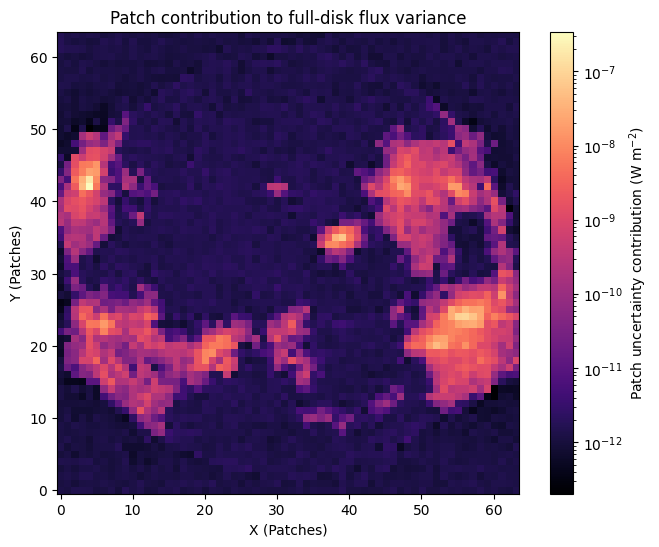

In [7]:
if result.intervals is None or result.patch_uncertainty_map is None:
    print("This checkpoint has no Gaussian uncertainty output.")
else:
    for level, (lower, upper) in result.intervals.items():
        print(f"{level}% model interval: [{lower:.3e}, {upper:.3e}] W/m²")
    fig, ax = plt.subplots(figsize=(8, 6))
    helio_foxes.plot_uncertainty_map(result, ax=ax)
    ax.set_title("Patch contribution to full-disk flux variance")
    plt.show()

assert predictions["Deterministic"].intervals is None
assert predictions["Deterministic"].patch_uncertainty_map is None

## 5. Flexible timestamps

The same timestamp formats work when fetching AIA, HARPs, and GOES, creating observations, or predicting from an array. Complete dates without a timezone are interpreted as UTC; date-only values mean midnight. Explicit timezone offsets are converted to UTC.

Use `parse_timestamp` to preview how an input will be interpreted. Ambiguous numeric dates, incomplete dates, and timezone abbreviations such as `EST` raise a descriptive error. Use a year-first date and an explicit UTC offset instead.

These sections require the updated `helio_foxes` package. If you installed the older bundled wheel, install the updated checkout into this notebook's environment and restart the kernel before running them.

In [8]:
timestamp_examples = [
    "2023-07-11T01:30:00Z",
    "2023/07/11 01:30",
    "2023.07.11_01:30:00_UTC",
    "July 11, 2023 01:30 UTC",
    "2023-07-10T21:30:00-04:00",
]
display(pd.DataFrame([
    {"Input": value, "Interpreted UTC": helio_foxes.parse_timestamp(value)}
    for value in timestamp_examples
]))

# An example of the error shown for an ambiguous input:
try:
    helio_foxes.parse_timestamp("07/11/2023")
except ValueError as exc:
    print(exc)

# Any accepted format can be used directly, for example:
# observation = processor.fetch_observation("2023/07/11 01:30")

,Input,Interpreted UTC
0,2023-07-11T01:30:00Z,2023-07-11 01:30:00+00:00
1,2023/07/11 01:30,2023-07-11 01:30:00+00:00
2,2023.07.11_01:30:00_UTC,2023-07-11 01:30:00+00:00
3,"July 11, 2023 01:30 UTC",2023-07-11 01:30:00+00:00
4,2023-07-10T21:30:00-04:00,2023-07-11 01:30:00+00:00


Invalid timestamp '07/11/2023': ambiguous numeric date; use year-month-day. Use a complete date such as '2023-08-01 12:00:00', '2023/08/01', or 'August 1, 2023'; use Z or a numeric UTC offset for timezone information.


## 6. Predict from your own data

If you already have a processed AIA stack, use `Observation.from_array`. The input must be a finite, channel-first `(7, H, W)` array in **94, 131, 171, 193, 211, 304, 335 Å** order. The checkpoint determines the required H and W (512 for these demo checkpoints).

The constructor records the timestamp and crop metadata and copies the data to float32. It does not calibrate, crop, resize, or normalize your input: match the training preprocessing and apply any matching AIA normalization artifact exactly once.

Here we reuse the processed observation above as an example of a user-supplied stack. You can replace it with `np.load("my_processed_stack.npy", allow_pickle=False)`. For a saved stack, `Observation.from_npy("my_processed_stack.npy", timestamp=TIMESTAMP)` is also available. Neither constructor downloads data. Optional HARP boxes and measured SXR data can travel with your observation.

Local observation UTC: 2023-07-11 01:30:00+00:00
Local AIA shape: (7, 512, 512)
Using mps for inference
Loading CoupledGaussianViTLocal model...
Predicted full-disk flux: 2.695e-06 W/m²


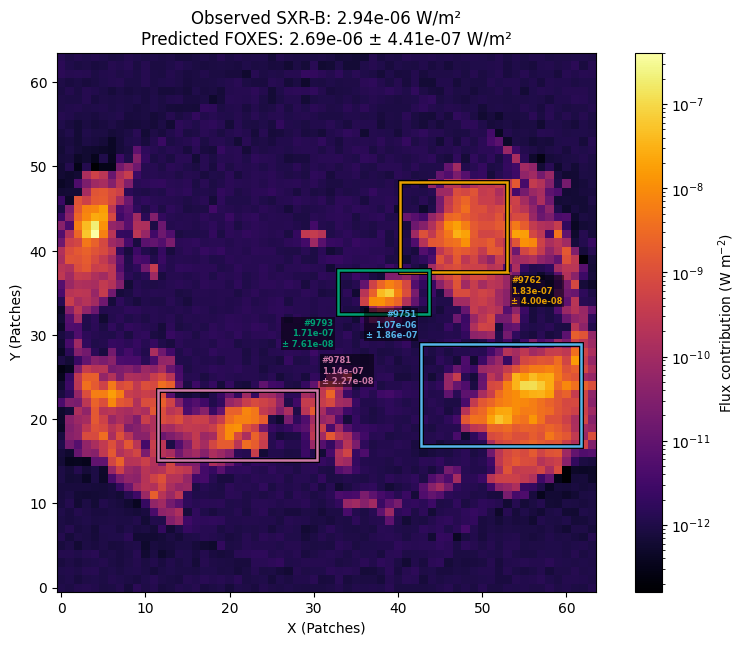

16253

In [9]:
my_stack = observation.data  # Replace with your own preprocessed (7, H, W) array.
my_observation = helio_foxes.Observation.from_array(
    my_stack,
    timestamp=observation.metadata.timestamp,
    wavelengths=observation.metadata.wavelengths,
    padding_factor=observation.metadata.padding_factor,
    harp_regions=observation.harp_regions,
    sxr=observation.sxr,
)
print("Local observation UTC:", my_observation.metadata.timestamp)
print("Local AIA shape:", my_observation.data.shape)

# Load once and reuse this predictor for further observations.
local_model = helio_foxes.load_model(CHECKPOINTS["Complex Gaussian"], device="auto")
local_prediction = local_model.predict(my_observation)
print(f"Predicted full-disk flux: {local_prediction.flux:.3e} W/m²")
fig, ax = plt.subplots(figsize=(10, 7))
helio_foxes.plot_flux_map(local_prediction, ax=ax, show_harp_boxes=True, min_harp_flux=1e-7)
plt.show()
del local_model
gc.collect()

### Starting with your own raw FITS files

`AIAProcessor.process_files` runs the same ITI preprocessing used by the downloader and preserves your FITS files. Supply one file for each wavelength, in the order shown below, from a consistent observation time. It returns the processed stack to wrap in an `Observation`; HARP/SXR fetching is separate.

```python
aia = helio_foxes.AIAProcessor(resolution=512)
paths = [Path("my_fits") / f"{wavelength}.fits" for wavelength in aia.WAVELENGTHS]
my_stack = aia.process_files(paths)
my_observation = helio_foxes.Observation.from_array(
    my_stack, timestamp="2023/07/11 01:30", harp_regions=[],
)
my_prediction = model.predict(my_observation)  # Use a loaded predictor.
```

`harp_regions=None` means no HARP query was requested; `[]` explicitly supplies no regions. To use your own HARP boxes, pass dictionaries with `HARPNUM` (or `harpnum`) and `top_pct`, `left_pct`, `width_pct`, `height_pct`, measured from the top-left display corner of this exact crop. Prediction itself does not query HARPs.

## 7. A time range and HARP light curves

Fetch and preprocess a range at a chosen cadence, then reuse one loaded model to predict each available observation. Set `RUN_RANGE_DEMO=True` to run this additional download. Choose RANGE_START, RANGE_END, and CADENCE below; the start and cadence-aligned end are included.

AIA uses one bulk JSOC record/segment query over the padded range, then downloads the selected frames and preprocesses complete seven-channel stacks. The native 12-second metadata query allows nearest-frame selection within tolerance for each requested time. HARP and GOES queries currently run per timestamp. Long ranges can produce large metadata responses, so split long jobs into smaller spans.

The iterator avoids retaining all AIA arrays. `on_error="skip"` logs individual AIA download/preprocessing failures and continues; omit it to raise instead. Bulk-query and prediction failures raise. Skipped AIA times are absent from the result. Use `list(processor.iter_observations(...))` when you want to retain all processed observations in memory.

`progress=True` displays tqdm while JSOC is queried and the observations are downloaded/preprocessed. The initial query stays at zero; the bar then advances per requested observation, including skipped attempts. When streaming into prediction, the ETA also includes prediction time. Set `SAVE_RANGE_OBSERVATIONS=True` to save complete NumPy archives before each prediction; saving remains optional.

`SNAPSHOT_TIME` selects the target image time. The example computes the query midpoint;
you can replace it with a timestamp such as `"2024-03-23 01:40"`.
During prediction, the API keeps one AIA channel image and replaces it whenever a
closer observation arrives. Equal-distance ties favor the earlier time. No temporary
image files are written.

`SHOW_AIA_SNAPSHOT=True` displays the retained prediction with the existing
`helio_foxes.plot_flux_map` function, followed by its plain AIA image. HARP colors match
the curves, and a vertical line marks the actual retained time. Change
`SNAPSHOT_WAVELENGTH` to choose the AIA channel. Set the toggle to `False` to predict
without retaining an image.

`SHOW_HARP_UNCERTAINTY` toggles regional uncertainty bands and matching flux-map
labels when supplied by the model. Deterministic models remain plain lines and labels.
`MIN_HARP_PEAK_FLUX` filters regions by their peak over the entire series, in W/m².
`HARP_LEGEND="auto"` uses a compact legend with the snapshot panels.

To change the snapshot time or wavelength, rerun the prediction cell. Saved observations
are reused when available. To change only the plot appearance, use the final plot cell
without predicting again.


Using mps for inference
Loading CoupledGaussianViTLocal model...


Querying JSOC:   0%|          | 0/30 [00:00<?, ?observation/s]

2026-10-29 16:57:44 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM73/D1733068138/S00000/image_lev1.fits
2026-10-29 16:57:44 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM83/D1733068116/S00000/image_lev1.fits
2026-10-29 16:57:44 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM74/D1733068137/S00000/image_lev1.fits
2026-10-29 16:57:44 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM78/D1733068120/S00000/image_lev1.fits
2026-10-29 16:57:56 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM83/D1733068139/S00000/image_lev1.fits
2026-10-29 16:57:57 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM80/D1733068121/S00000/image_lev1.fits
2026-10-29 16:57:59 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM76/D1733068117/S00000/image_lev1.fits
2026-10-29 16:58:14 - helio_foxes.api - INFO: Querying JSOC via drms: hmi.sharp_720s[][2024.03.23_00:30:00_TAI/1800s]
2026-10-29 16:58:22 - root - INFO: Downloading: http://jsoc.stanford.edu/SUM81/D1733

Successful predictions: 121
Retained snapshot (UTC): 2024-03-23 01:45:00+00:00


,flux,observed_xrsb_flux
timestamp,,
2024-03-23 00:45:00+00:00,0.000004,0.000004
2024-03-23 00:46:00+00:00,0.000005,0.000005
2024-03-23 00:47:00+00:00,0.000005,0.000005
2024-03-23 00:48:00+00:00,0.000005,0.000005
2024-03-23 00:49:00+00:00,0.000005,0.000005
...,...,...
2024-03-23 02:41:00+00:00,0.000053,0.000042
2024-03-23 02:42:00+00:00,0.000052,0.000041
2024-03-23 02:43:00+00:00,0.000051,0.000040


Available HARPs: [10952, 10957, 10959, 10973, 10975, 10976, 10987, 10990, 10991, 10995, 10997, 10998]
HARP 10952 light curve:


,flux_sum,flux_sum_uncertainty
timestamp,,
2024-03-23 00:45:00+00:00,2.005053e-07,5.969407e-08
2024-03-23 00:46:00+00:00,1.964120e-07,5.865666e-08
2024-03-23 00:47:00+00:00,1.966435e-07,5.896997e-08
2024-03-23 00:48:00+00:00,1.923607e-07,5.715898e-08
2024-03-23 00:49:00+00:00,1.940092e-07,5.804908e-08
...,...,...
2024-03-23 02:41:00+00:00,1.423546e-07,4.672269e-08
2024-03-23 02:42:00+00:00,1.447295e-07,4.798482e-08
2024-03-23 02:43:00+00:00,1.445653e-07,4.831128e-08


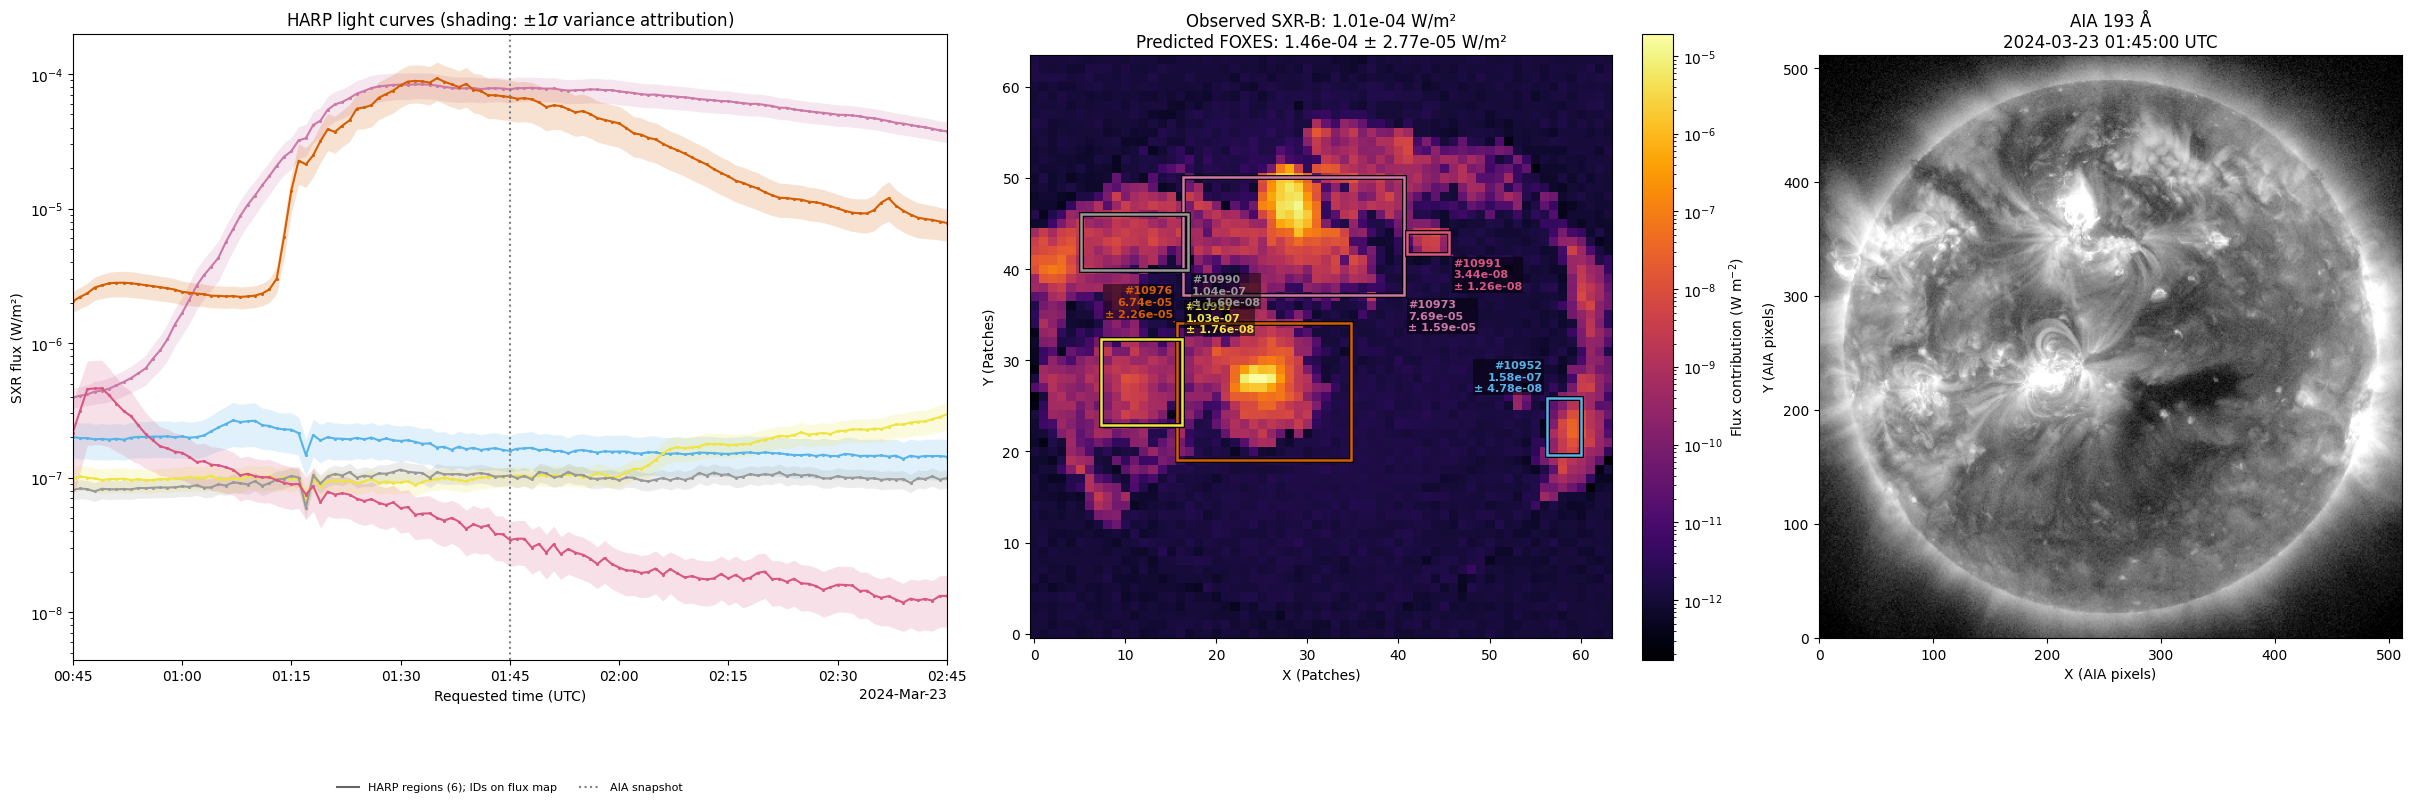

In [13]:
RUN_RANGE_DEMO = True  # Enable to download and predict this additional range.
RANGE_START = "2024-03-23 00:45"
RANGE_END = "2024-03-23 02:45"
CADENCE = "1min"  # Also accepts timedelta or numeric seconds, in whole seconds.

SHOW_AIA_SNAPSHOT = True  # Toggle the flux-map and plain AIA panels.
SNAPSHOT_WAVELENGTH = 193
query_start = helio_foxes.parse_timestamp(RANGE_START)
query_end = helio_foxes.parse_timestamp(RANGE_END)
SNAPSHOT_TIME = query_start + (query_end - query_start) / 2  # Or supply any timestamp.
MIN_HARP_PEAK_FLUX = 1e-7  # W/m²; e.g. 1e-7 to hide weak regions.
HARP_LEGEND = "auto"  # Compact with snapshots; also full / compact / none.
SHOW_HARP_UNCERTAINTY = True  # Shading/labels appear only for models with uncertainty.

SAVE_RANGE_OBSERVATIONS = True  # Enable to save each processed observation before prediction.
SAVED_OBSERVATIONS_DIR = DEMO_DIR / "saved_observations"

if RUN_RANGE_DEMO:
    range_observations = processor.iter_observations(
        RANGE_START, RANGE_END, cadence=CADENCE, on_error="skip",
        progress=True,
        save_dir=SAVED_OBSERVATIONS_DIR if SAVE_RANGE_OBSERVATIONS else None,
        overwrite=False,  # Reuse saved observations; True forces downloading/preprocessing again.
    )
    range_model = helio_foxes.load_model(CHECKPOINTS["Complex Gaussian"], device="auto")
    try:
        series = range_model.predict_series(
            range_observations, snapshot_time=SNAPSHOT_TIME if SHOW_AIA_SNAPSHOT else None,
            snapshot_wavelength=SNAPSHOT_WAVELENGTH,
        )
    finally:
        range_observations.close()
        del range_model
        gc.collect()

    print("Successful predictions:", len(series.predictions))
    if series.snapshot is not None:
        print("Retained snapshot (UTC):", series.snapshot.metadata.timestamp)
    display(series.to_dataframe())  # Full-disk flux and measured XRS-B, W/m².
    harp_curves = series.harp_light_curves()  # {integer HARP number: DataFrame}
    print("Available HARPs:", list(harp_curves))
    if harp_curves:
        example_harp = next(iter(harp_curves))
        print(f"HARP {example_harp} light curve:")
        display(harp_curves[example_harp])
        ax = series.plot(
            show_snapshot=SHOW_AIA_SNAPSHOT,
            show_uncertainty=SHOW_HARP_UNCERTAINTY,
            min_peak_flux=MIN_HARP_PEAK_FLUX, legend=HARP_LEGEND,
        )  # Or harpnums=[example_harp] to select one region.
        plt.show()
    else:
        print("No HARP regions were returned for the successful observations.")

    # Returned tables can be saved or passed to your own plotting code:
    # series.to_dataframe().to_csv("full_disk_light_curve.csv")
    # for harpnum, curve in harp_curves.items():
    #     curve.to_csv(f"harp_{harpnum}.csv")
else:
    print("Set RUN_RANGE_DEMO=True to fetch the range and plot HARP light curves.")

Each HARP table has `flux_sum` and `flux_sum_uncertainty` columns in W/m², indexed by requested UTC time. Missing regions at successful observation times produce `NaN` and breaks in plotted lines; nothing is zero-filled or interpolated. HARP query failures can also produce gaps. Regional sums use the same positive patch-center box contributions as the earlier map, including overlapping boxes. Gaussian regional uncertainty is an additive variance attribution, not a calibrated local error bar.

For a full-disk comparison with measured GOES, use `series.plot(harpnums=[], include_full_disk=True, include_sxr=True)`. The times are requested times, not individual AIA exposure times; nearby requests can select the same exposure.

## 8. Save observations and predict later

Enable `SAVE_RANGE_OBSERVATIONS` in section 7 to keep each processed observation in `saved_observations/`. Each compressed NumPy `.npz` archive contains the AIA array and its UTC timestamp, wavelength order, crop geometry, HARP rows, and measured SXR data. This preserves the information needed for later HARP light curves.

`load_observations` reads one archive at a time without downloading or preprocessing again. Keep the same model normalization settings you used for the original observations: the loader does not add another transform. The cell below reloads the saved range when files are available and reuses one checkpoint for all predictions.

You can also download and save without predicting:
```python
for saved_observation in processor.iter_observations(
    RANGE_START, RANGE_END, cadence=CADENCE,
    save_dir=SAVED_OBSERVATIONS_DIR, progress=True,
):
    print(saved_observation.metadata.timestamp)  # Already saved.
```

For one complete observation:
```python
path = observation.save(DEMO_DIR / "one_observation.npz")
restored = helio_foxes.Observation.load(path)
```

`iter_observations(..., save_dir=...)` automatically reuses existing archives: saved observations are loaded and yielded without downloading, preprocessing, or HARP/SXR queries. Only missing times are processed, so rerunning a partially completed range resumes the remaining work. A fully saved range needs no data queries. Pass `overwrite=True` to refresh existing observations deliberately. Cached metadata and enabled-source contents are reused as saved; refresh after changing preprocessing or query settings. Corrupt caches and save failures raise, even with `on_error="skip"`. Standalone `observation.save(path)` still requires `overwrite=True` to replace a file. Use `np.save` and `Observation.from_npy` instead if you only want a plain array without its metadata.

`SHOW_SAVED_AIA_SNAPSHOT` toggles the flux-map and AIA panels for the reloaded range.
Set `SAVED_SNAPSHOT_TIME` to choose the nearest saved observation. Only one channel from that observation is retained; no new data are downloaded.


Reloading 91 observations from /Users/griffingoodwin/Documents/gitrepos/2026-HL-FOXES-CORE/tutorials/heliofoxes_demo/saved_observations
Using mps for inference
Loading CoupledGaussianViTLocal model...


Loading observations:   0%|          | 0/91 [00:00<?, ?observation/s]

Retained snapshot (UTC): 2024-03-23 01:45:00+00:00


,flux,observed_xrsb_flux
timestamp,,
2024-03-23 01:00:00+00:00,0.000006,0.000005
2024-03-23 01:01:00+00:00,0.000006,0.000006
2024-03-23 01:02:00+00:00,0.000007,0.000006
2024-03-23 01:03:00+00:00,0.000007,0.000006
2024-03-23 01:04:00+00:00,0.000007,0.000007
...,...,...
2024-03-23 02:26:00+00:00,0.000068,0.000053
2024-03-23 02:27:00+00:00,0.000067,0.000052
2024-03-23 02:28:00+00:00,0.000066,0.000052


Reloaded HARP numbers: [10952, 10957, 10959, 10973, 10975, 10976, 10987, 10990, 10991, 10995, 10997, 10998]


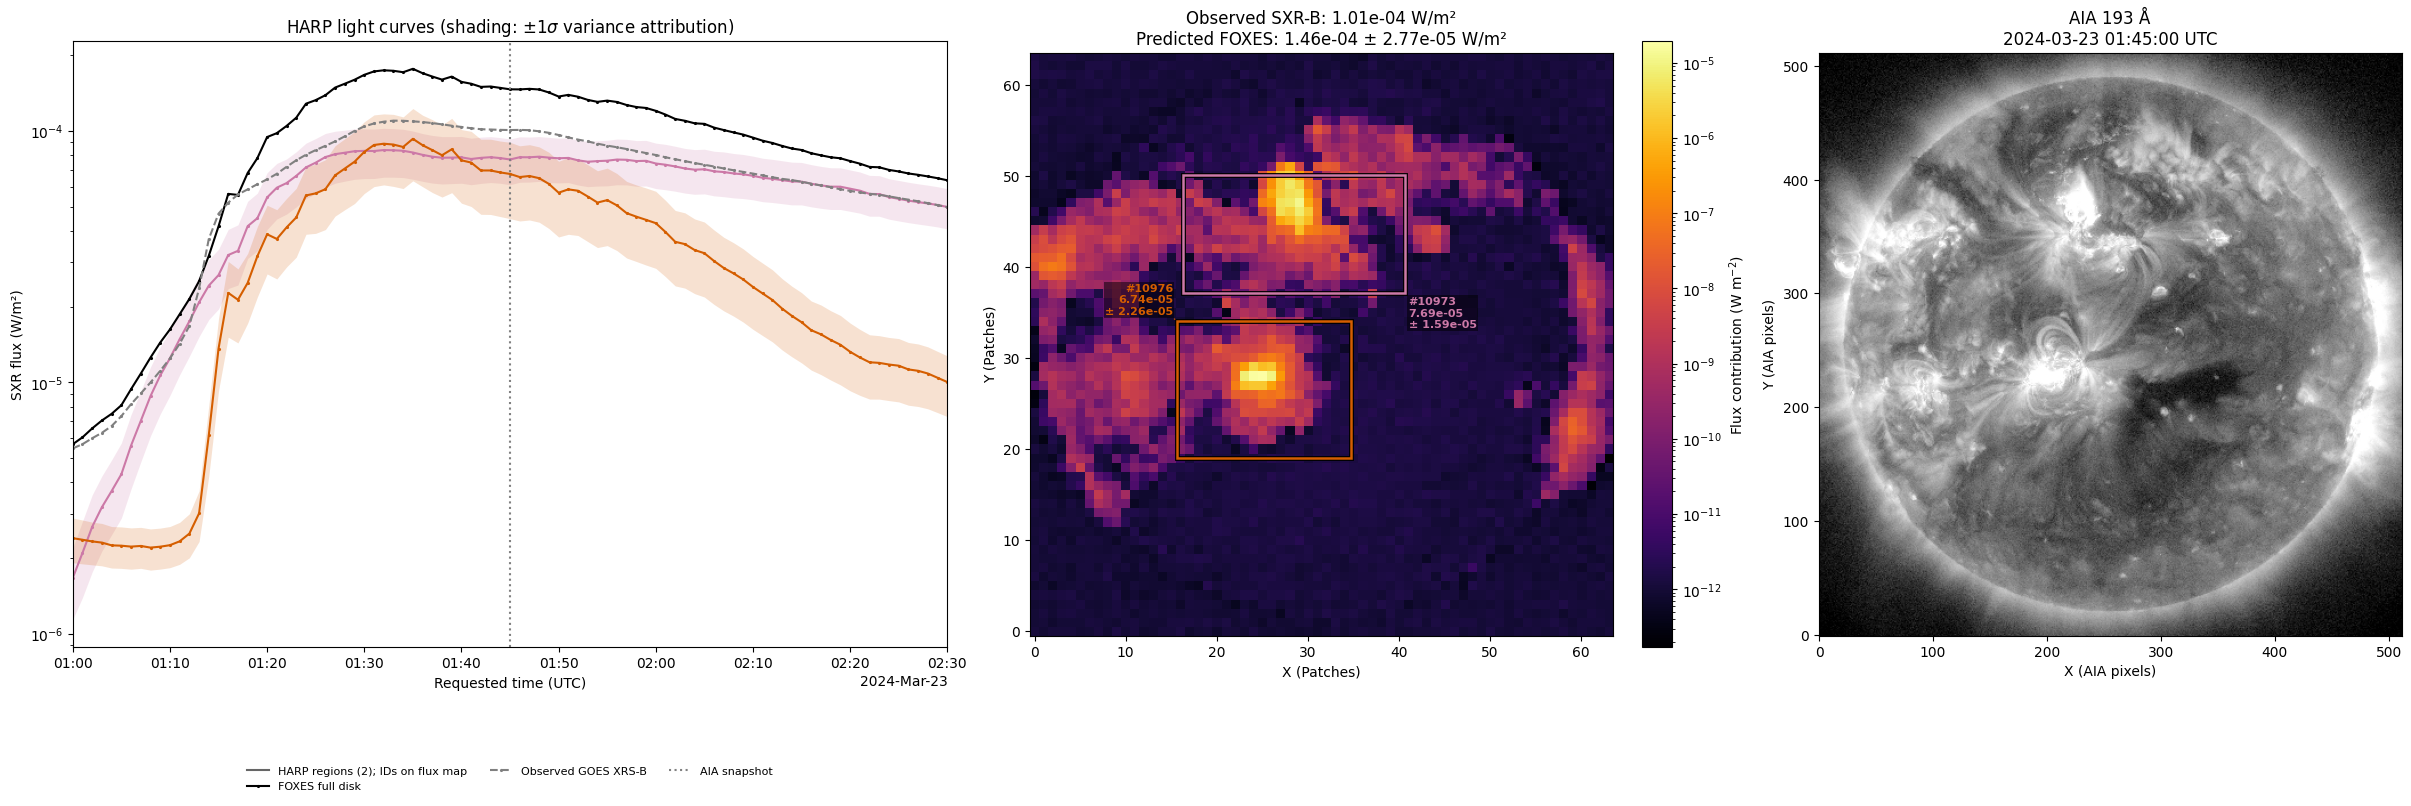

In [11]:
SAVED_SNAPSHOT_TIME = "2024-03-23 01:45"  # Nearest available saved observation.
SHOW_SAVED_AIA_SNAPSHOT = True  # False retains no image.
SAVED_SNAPSHOT_WAVELENGTH = 193

SHOW_SAVED_UNCERTAINTY = True
SAVED_MIN_HARP_PEAK_FLUX = 1e-6 # W/m²; threshold over the whole series.
SAVED_HARP_LEGEND = "auto"

saved_observation_directory = DEMO_DIR / "saved_observations"
saved_observation_paths = sorted(saved_observation_directory.glob("*.npz"))
if saved_observation_paths:
    print(f"Reloading {len(saved_observation_paths)} observations from {saved_observation_directory}")
    saved_observations = helio_foxes.load_observations(saved_observation_directory, progress=True)
    reload_model = helio_foxes.load_model(CHECKPOINTS["Complex Gaussian"], device="auto")
    try:
        reloaded_series = reload_model.predict_series(
            saved_observations,
            snapshot_time=SAVED_SNAPSHOT_TIME if SHOW_SAVED_AIA_SNAPSHOT else None,
            snapshot_wavelength=SAVED_SNAPSHOT_WAVELENGTH,
        )
    finally:
        saved_observations.close()
        del reload_model
        gc.collect()

    if reloaded_series.snapshot is not None:
        print("Retained snapshot (UTC):", reloaded_series.snapshot.metadata.timestamp)
    display(reloaded_series.to_dataframe())
    reloaded_harp_curves = reloaded_series.harp_light_curves()
    print("Reloaded HARP numbers:", list(reloaded_harp_curves))
    if reloaded_harp_curves:
        ax = reloaded_series.plot(
            show_snapshot=SHOW_SAVED_AIA_SNAPSHOT,
            show_uncertainty=SHOW_SAVED_UNCERTAINTY,
            min_peak_flux=SAVED_MIN_HARP_PEAK_FLUX,
            legend=SAVED_HARP_LEGEND, include_sxr=True, include_full_disk=True,
        )
        plt.show()
else:
    print("No saved observations yet. Enable SAVE_RANGE_OBSERVATIONS and run section 7 first.")

### Adjust the light-curve display without repeating prediction

Run the range or saved-observation section once, then rerun this plot cell to
change the peak threshold, legend, uncertainty shading, or snapshot visibility.
The snapshot is the image retained nearest the target time supplied during prediction.
The SXR axis is logarithmic; nonpositive values are displayed as gaps.
Models without uncertainties have plain curves and labels.

The plot uses the already retained image. Changing its target time or wavelength
requires rerunning section 7 or 8. If prediction retained no image, this cell
displays only the curves even when the snapshot display toggle is enabled.


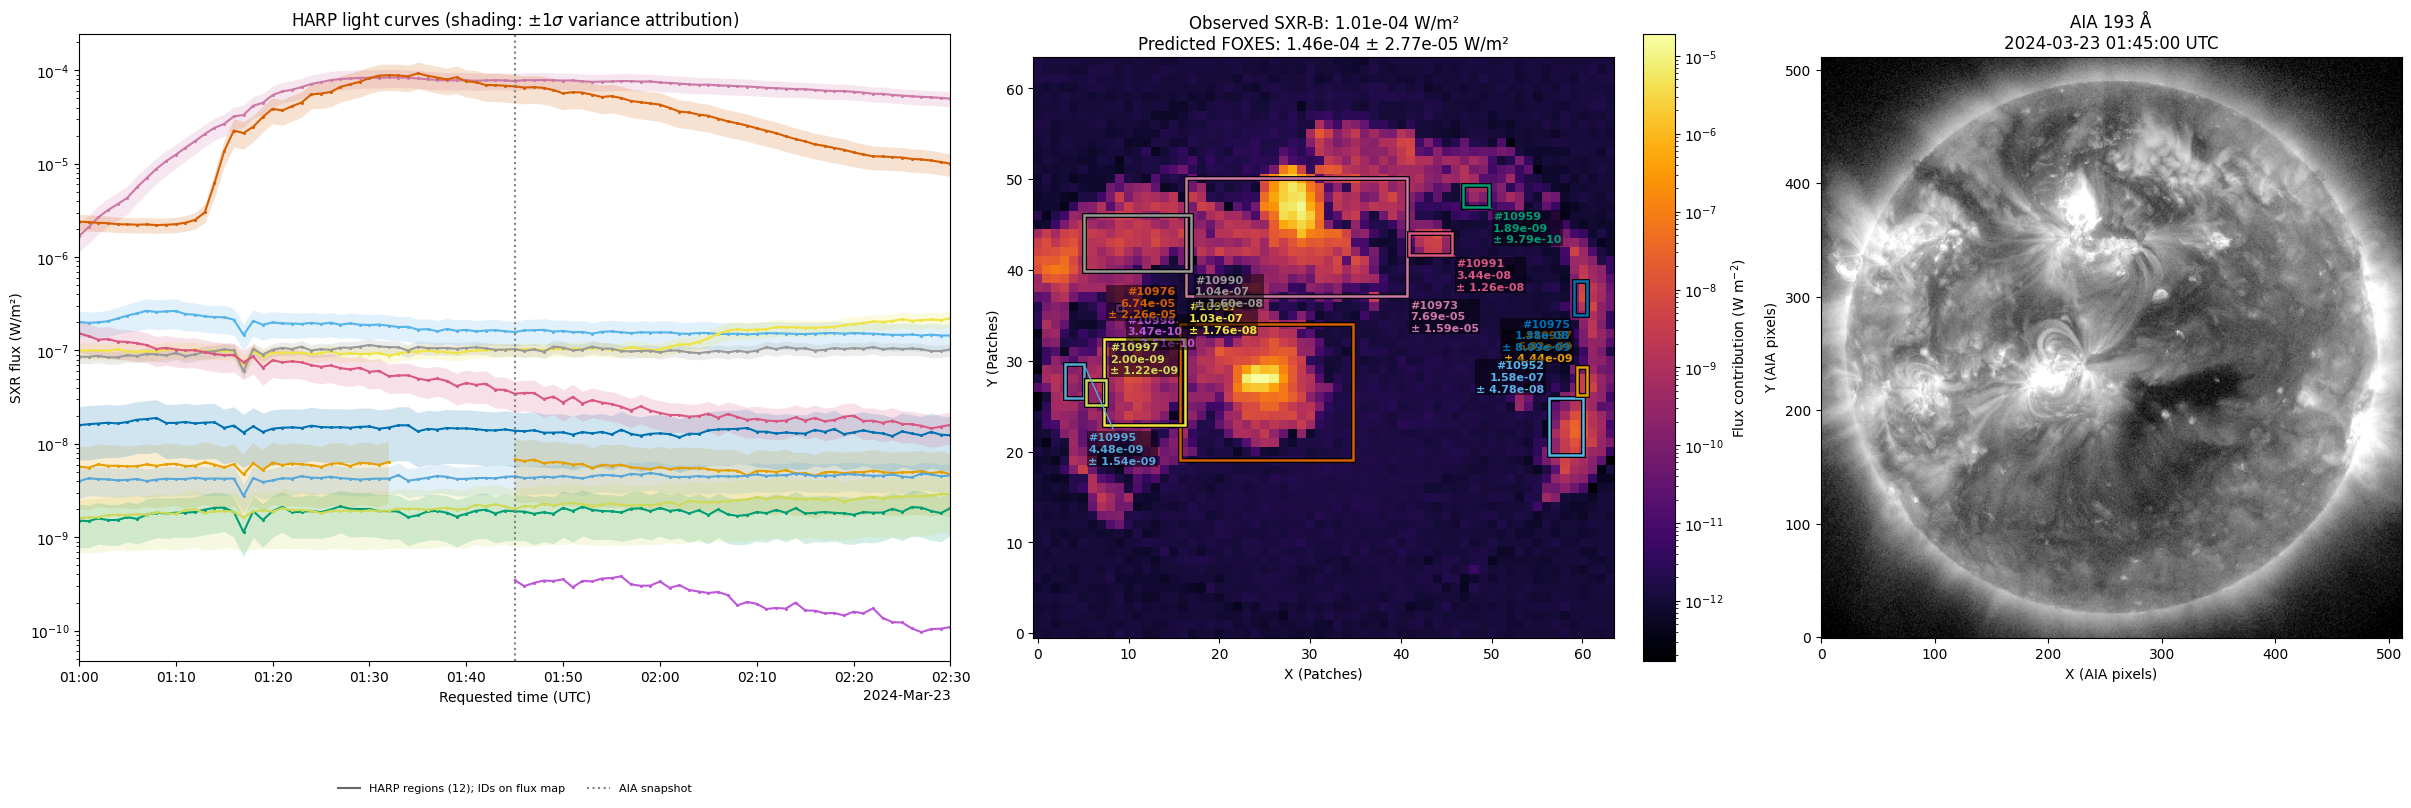

In [12]:
SHOW_SELECTED_SNAPSHOT = True  # Show the retained image, if available.
SHOW_SELECTED_UNCERTAINTY = True
SELECTED_MIN_PEAK_FLUX = 0.0  # Try 1e-7; no new downloads/predictions.
SELECTED_LEGEND = "auto"  # full / compact / none are also available.

series_to_plot = globals().get("reloaded_series", globals().get("series"))
if series_to_plot is None:
    print("Run section 7 or 8 first to create a prediction series.")
else:
    ax = series_to_plot.plot(
        show_snapshot=SHOW_SELECTED_SNAPSHOT and series_to_plot.snapshot is not None,
        show_uncertainty=SHOW_SELECTED_UNCERTAINTY,
        min_peak_flux=SELECTED_MIN_PEAK_FLUX, legend=SELECTED_LEGEND,
    )
    plt.show()